# 02 — EDA complète : les 12 investigations de l'énoncé §5.1

**Projet** : fraud-risk-intelligence-prototype — **Phase** : manques C2 du J2 (PR 15, I76 ①, fondateur, hors dépôt)
**IDs** : A05, A06, A07, A08 (`docs/specs/Features_Complet.md`) — **Matrice** : R061–R074, R081, R082
**Registre** : n° 14bis (hors registre, à ajouter au registre v1.6 par le fondateur)

Ce notebook **complète** `01_eda.ipynb` (gelé) sans le modifier. Il :
- charge les données **seulement** par `load_raw()` (n° 10), qui valide aussi le schéma ;
- n'affiche **que des agrégats** : aucune ligne brute, aucun identifiant de compte ;
- n'écrit que des figures nouvelles `artifacts/figures/eda2_*.png` (jamais `fig01` à `fig10`) ;
- ne modifie aucune donnée et **ne change aucune décision J3** : un constat qui la questionne va en question au fondateur (`PASSATION.md` §6).

Chaque section porte le n° de la Matrice (R061 à R072), dans l'ordre de l'énoncé §5.1. La liste « constat → décision » (A08) est à la fin.

In [1]:
import os
from pathlib import Path
# Move to the repository root (the folder that contains src/), without any personal path (I58, Q-03)
_root = Path(os.getcwd()).resolve()
while not (_root / "src").is_dir() and _root != _root.parent:
    _root = _root.parent
os.chdir(_root)

In [2]:
# Imports — data are loaded ONLY by load_raw() (n° 10); the contract comes from schema.py (n° 09).
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data.load_paysim import load_raw
from src.data.schema import COLUMNS, DTYPES, TARGET_COLUMN, TRANSACTION_TYPES

FIG_DIR = Path("artifacts/figures")
FLAG_COLUMN = "isFlaggedFraud"
RISKY_TYPES = ["TRANSFER", "CASH_OUT"]   # checked again in R068, not assumed
CENT = 0.01                              # balance-check tolerance: amounts are written to the cent
pd.set_option("display.width", 140)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def save_eda2_fig(fig, name):
    """Save a figure of THIS notebook only. The `eda2_` prefix guarantees that the J2 figures
    (fig01 to fig10, written by eda.py and train.py) are never overwritten."""
    if not (name.startswith("eda2_") and name.endswith(".png")):
        raise ValueError(f"Figure name must be eda2_*.png, got {name!r}")
    path = FIG_DIR / name
    fig.savefig(path, dpi=110, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {path}")

print("Imports OK")

Imports OK


In [3]:
t0 = time.perf_counter()
df = load_raw()   # also validates the schema (validate_frame): a missing column or bad type stops here
print(f"Loaded in {time.perf_counter() - t0:.1f} s")
print(f"Memory used by the frame: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Loaded in 6.7 s


Memory used by the frame: 1.52 GB


## R061 — 1. Dimensions et schéma

In [4]:
n_rows, n_cols = df.shape
print(f"Rows: {n_rows:,}")
print(f"Columns: {n_cols}")
schema_table = pd.DataFrame(
    {
        "column": [spec.name for spec in COLUMNS],
        "contract_type": [spec.kind for spec in COLUMNS],
        "role": [spec.role for spec in COLUMNS],
        "pandas_dtype": [str(df[spec.name].dtype) for spec in COLUMNS],
    }
)
print(schema_table.to_string(index=False))
print("Columns in the file but not in the contract:", sorted(set(df.columns) - set(schema_table["column"])))

Rows: 6,362,620
Columns: 11
        column contract_type       role pandas_dtype
          step       integer    feature        int64
          type          text    feature       object
        amount        number    feature      float64
      nameOrig          text identifier       object
 oldbalanceOrg        number    feature      float64
newbalanceOrig        number    feature      float64
      nameDest          text identifier       object
oldbalanceDest        number    feature      float64
newbalanceDest        number    feature      float64
       isFraud       integer     target        int64
isFlaggedFraud       integer  rule_flag        int64
Columns in the file but not in the contract: []


**Constat.** Le fichier chargé compte **6,362,620 lignes** et **11 colonnes**, exactement les 11 colonnes du contrat `schema.py` (aucune colonne en plus ni en moins). Rôles : 7 variables (`feature`), 2 identifiants (`nameOrig`, `nameDest`), 1 cible (`isFraud`), 1 sortie de règle du simulateur (`isFlaggedFraud`, rôle `rule_flag`). Le tableau tient en mémoire (1.52 GB).

## R062 — 2. Types vérifiés contre leur sens

In [5]:
# Each type checked against its meaning (aggregates only, never a raw value of an identifier).
checks = []
checks.append(("step", "integer >= 1 (simulated hour)", f"{df['step'].dtype}, min {df['step'].min()}, max {df['step'].max()}",
               bool(pd.api.types.is_integer_dtype(df["step"]) and df["step"].min() >= 1)))
observed_types = sorted(df["type"].unique())
checks.append(("type", "one of 5 categories", f"{len(observed_types)} values: {observed_types}",
               set(observed_types) == set(TRANSACTION_TYPES)))
for col in ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]:
    checks.append((col, "float >= 0 (money)", f"{df[col].dtype}, min {df[col].min():,.2f}",
                   bool(pd.api.types.is_float_dtype(df[col]) and df[col].min() >= 0)))
for col in ["nameOrig", "nameDest"]:
    # Identifier: text; only the FIRST LETTER is summarised (account category), never a value.
    letters = sorted(df[col].str[0].unique())
    checks.append((col, "text identifier", f"{df[col].dtype}, first letters {letters}",
                   df[col].dtype == object))
for col in [TARGET_COLUMN, FLAG_COLUMN]:
    values = sorted(int(v) for v in df[col].unique())
    checks.append((col, "binary 0/1", f"{df[col].dtype}, values {values}", set(values) <= {0, 1}))
type_check = pd.DataFrame(checks, columns=["column", "expected_meaning", "observed", "ok"])
print(type_check.to_string(index=False))
print("All types match their meaning:", bool(type_check["ok"].all()))

        column              expected_meaning                                                          observed   ok
          step integer >= 1 (simulated hour)                                             int64, min 1, max 743 True
          type           one of 5 categories 5 values: ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER'] True
        amount            float >= 0 (money)                                                 float64, min 0.00 True
 oldbalanceOrg            float >= 0 (money)                                                 float64, min 0.00 True
newbalanceOrig            float >= 0 (money)                                                 float64, min 0.00 True
oldbalanceDest            float >= 0 (money)                                                 float64, min 0.00 True
newbalanceDest            float >= 0 (money)                                                 float64, min 0.00 True
      nameOrig               text identifier                            

**Constat.** Chaque type correspond à son sens : `step` entier de 1 à 743, `type` dans les 5 catégories attendues, montants et soldes en flottants jamais négatifs, identifiants en texte (premières lettres : `C` pour `nameOrig` ; `C` et `M` pour `nameDest`), `isFraud` et `isFlaggedFraud` binaires 0/1.
**Décision.** Aucune correction de type nécessaire. Les types sont forcés dès la lecture (`DTYPES`) et `validate_frame` refuse un fichier non conforme (testé par `tests/test_data_schema.py`, `test_load_raw_invalid`).

## R063 — 3. Valeurs manquantes par colonne

In [6]:
missing = df.isna().sum().rename("missing_count").to_frame()
missing["missing_pct"] = 100 * missing["missing_count"] / len(df)
print(missing.to_string())
print(f"Total missing cells: {int(missing['missing_count'].sum()):,}")

                missing_count  missing_pct
step                        0       0.0000
type                        0       0.0000
amount                      0       0.0000
nameOrig                    0       0.0000
oldbalanceOrg               0       0.0000
newbalanceOrig              0       0.0000
nameDest                    0       0.0000
oldbalanceDest              0       0.0000
newbalanceDest              0       0.0000
isFraud                     0       0.0000
isFlaggedFraud              0       0.0000
Total missing cells: 0


**Constat.** 0 valeur manquante dans chacune des 11 colonnes (total : 0).
**Décision (R081).** Aucune imputation : il n'y a rien à traiter. Le contrat existant reste la règle : `validate_frame` refuse une cible manquante ; une variable manquante n'est pas refusée au chargement (`schema.py`). Si une autre copie du fichier contenait des manquants, cette section les compterait et le fondateur déciderait de la règle.

## R064 — 4. Doublons

**Définitions, écrites avant tout compte :**
- **D1 — ligne entière identique** : les 11 colonnes sont égales à celles d'une ligne précédente.
- **D2 — même événement** : mêmes `step`, `type`, `amount`, `nameOrig` et `nameDest`, même si les soldes ou l'étiquette diffèrent.
- **D2 à étiquette contradictoire** : groupe D2 dont les lignes n'ont pas toutes le même `isFraud` (le cas le plus grave).
- **Contexte, pas un doublon** : un même `nameOrig` ou `nameDest` qui revient sur plusieurs lignes (clients ou destinataires réutilisés).

On compte les lignes **en plus** de la première de chaque groupe. Seuls des comptes sont affichés, jamais une ligne.

In [7]:
# D1 — the whole row (11 columns) is identical to an earlier row.
d1 = int(df.duplicated(keep="first").sum())
# D2 — same event key: step, type, amount, nameOrig, nameDest (balances or labels may differ).
D2_KEY = ["step", "type", "amount", "nameOrig", "nameDest"]
d2_mask_all = df.duplicated(subset=D2_KEY, keep=False)
d2 = int(df.duplicated(subset=D2_KEY, keep="first").sum())
# D2 groups whose label differs (contradictory labels) — computed only on the duplicated rows.
if d2_mask_all.any():
    d2_conflicts = int((df.loc[d2_mask_all].groupby(D2_KEY)[TARGET_COLUMN].nunique() > 1).sum())
else:
    d2_conflicts = 0
print(f"D1 extra rows (whole row identical): {d1:,}")
print(f"D2 extra rows (same step/type/amount/nameOrig/nameDest): {d2:,}")
print(f"D2 groups with different isFraud labels: {d2_conflicts:,}")
# Context, NOT a duplicate: customers who appear more than once as origin / recipients reused.
n_orig_unique = df["nameOrig"].nunique()
n_orig_repeated_rows = int(df["nameOrig"].duplicated(keep=False).sum())
n_dest_unique = df["nameDest"].nunique()
print(f"Distinct nameOrig: {n_orig_unique:,} ; rows whose nameOrig appears more than once: {n_orig_repeated_rows:,}")
print(f"Distinct nameDest: {n_dest_unique:,} ; mean rows per nameDest: {len(df) / n_dest_unique:.2f}")
del d2_mask_all

D1 extra rows (whole row identical): 0
D2 extra rows (same step/type/amount/nameOrig/nameDest): 0
D2 groups with different isFraud labels: 0


Distinct nameOrig: 6,353,307 ; rows whose nameOrig appears more than once: 18,611
Distinct nameDest: 2,722,362 ; mean rows per nameDest: 2.34


**Constat.** D1 = 0, D2 = 0, groupes D2 à étiquette contradictoire = 0. Contexte : 6,353,307 `nameOrig` distincts pour 6,362,620 lignes (18,611 lignes ont un `nameOrig` qui revient) ; 2,722,362 `nameDest` distincts (2.34 lignes par destinataire en moyenne).
**Décision (R082).** Aucun doublon : aucune ligne retirée. Les identifiants restent exclus des variables (I36) : un `nameOrig` presque toujours unique ne porte rien de général, et un `nameDest` réutilisé pourrait être mémorisé.

## R065 — 5. Cible et déséquilibre des classes

           count     pct
isFraud                 
0        6354407 99.8709
1           8213  0.1291
Frauds: 8,213 ; legitimate: 6,354,407 ; about 1 fraud for 774 legitimate
Accuracy of a model that always answers 'not fraud': 99.8709 %


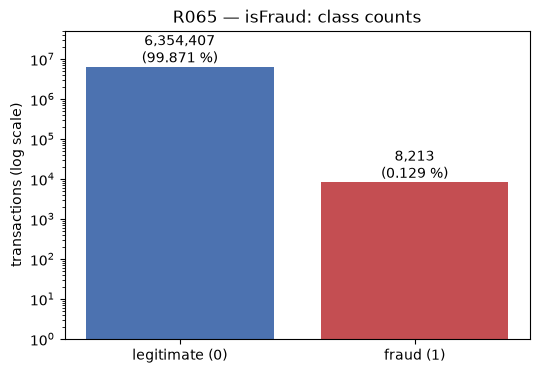

Saved: artifacts/figures/eda2_class_imbalance.png


In [8]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
target_table = pd.DataFrame({"count": target_counts, "pct": 100 * target_counts / len(df)})
print(target_table.to_string())
n_fraud = int(target_counts.get(1, 0))
n_legit = int(target_counts.get(0, 0))
print(f"Frauds: {n_fraud:,} ; legitimate: {n_legit:,} ; about 1 fraud for {n_legit / n_fraud:,.0f} legitimate")
print(f"Accuracy of a model that always answers 'not fraud': {100 * n_legit / len(df):.4f} %")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["legitimate (0)", "fraud (1)"], [n_legit, n_fraud], color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("transactions (log scale)")
ax.set_title("R065 — isFraud: class counts")
for i, v in enumerate([n_legit, n_fraud]):
    ax.text(i, v, f"{v:,}\n({100 * v / len(df):.3f} %)", ha="center", va="bottom")
ax.set_ylim(1, n_legit * 8)
save_eda2_fig(fig, "eda2_class_imbalance.png")

**Constat.** 8,213 fraudes (0.1291 %) contre 6,354,407 transactions légitimes (99.8709 %), soit environ 1 fraude pour 774 légitimes. Un modèle qui répond toujours « pas fraude » aurait une accuracy de 99.8709 % sans trouver une seule fraude.

**Figure `eda2_class_imbalance.png`.**
1. *Ce qu'elle montre* : les deux classes sur une échelle logarithmique ; la fraude représente 0.1291 % des transactions.
2. *Implication pour Northstar* : les relecteurs cherchent environ 1 fraude parmi 774 transactions ; une mesure globale comme l'accuracy cacherait un modèle qui ne trouve rien.
3. *Décision éclairée* : métriques PR-AUC, précision et rappel au seuil (I09, I08) plutôt que l'accuracy, et découpage stratifié sur `isFraud` (I34) pour garder la même proportion de fraudes dans chaque partie.

## R066 — 6. Types de transaction

In [9]:
type_counts = df["type"].value_counts()
type_table = pd.DataFrame({"count": type_counts, "share_pct": 100 * type_counts / len(df)})
print(type_table.to_string())

            count  share_pct
type                        
CASH_OUT  2237500    35.1663
PAYMENT   2151495    33.8146
CASH_IN   1399284    21.9923
TRANSFER   532909     8.3756
DEBIT       41432     0.6512


**Constat.** CASH_OUT 2237500 (35.1663 %), PAYMENT 2151495 (33.8146 %), CASH_IN 1399284 (21.9923 %), TRANSFER 532909 (8.3756 %), DEBIT 41432 (0.6512 %). Le graphique est commun avec R068 (`eda2_type_volume_fraud_rate.png`).

## R067 — 7. Distribution des montants

amount == 0: 16 rows, of which fraud: 16


count    6,362,620.0000
mean       179,861.9035
std        603,858.2315
min              0.0000
1%             449.4676
25%         13,389.5700
50%         74,871.9400
75%        208,721.4775
99%      1,615,979.4716
max     92,445,516.6400
Skewness of amount: 30.99
log10 computed on amount > 0 only: 6,362,604 rows ; all values finite: True
Skewness of log10(amount): -0.56
Median amount by class:


isFraud
0    74,684.7200
1   441,423.4400


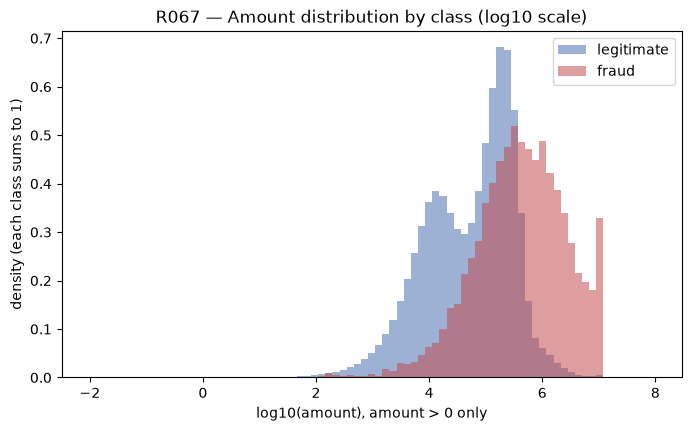

Saved: artifacts/figures/eda2_amount_distribution.png


In [10]:
# Zero amounts are counted BEFORE any log10 (log10(0) = -inf).
zero_amount = df["amount"] == 0
n_zero = int(zero_amount.sum())
n_zero_fraud = int((zero_amount & (df[TARGET_COLUMN] == 1)).sum())
print(f"amount == 0: {n_zero:,} rows, of which fraud: {n_zero_fraud:,}")
print(df["amount"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).to_string())
print(f"Skewness of amount: {df['amount'].skew():.2f}")
positive = df.loc[~zero_amount, ["amount", TARGET_COLUMN]]
log_amount = np.log10(positive["amount"])
print(f"log10 computed on amount > 0 only: {len(positive):,} rows ; all values finite: {bool(np.isfinite(log_amount).all())}")
print(f"Skewness of log10(amount): {log_amount.skew():.2f}")
print("Median amount by class:")
print(df.groupby(TARGET_COLUMN)["amount"].median().to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(log_amount.min(), log_amount.max(), 80)
for label, colour, name in [(0, "#4C72B0", "legitimate"), (1, "#C44E52", "fraud")]:
    ax.hist(log_amount[positive[TARGET_COLUMN] == label], bins=bins, density=True, alpha=0.55,
            color=colour, label=name)
ax.set_xlabel("log10(amount), amount > 0 only")
ax.set_ylabel("density (each class sums to 1)")
ax.set_title("R067 — Amount distribution by class (log10 scale)")
ax.legend()
save_eda2_fig(fig, "eda2_amount_distribution.png")
del positive, log_amount

**Montants à 0 (comptés avant tout log10).** 16 transactions ont `amount == 0`, et toutes les 16 sont des fraudes. Le log10 n'est calculé que sur `amount > 0` (6,362,604 lignes) : aucune valeur infinie (vérifié : toutes finies).

**Constat.** Médiane 74,871.9400, moyenne 179,861.9035, 99ᵉ centile 1,615,979.4716, maximum 92,445,516.6400. Asymétrie (skewness) de `amount` : 30.99, très forte à droite ; après log10, elle tombe à -0.56. Médiane des montants : 74,684.7200 pour les légitimes, 441,423.4400 pour les fraudes.

**Figure `eda2_amount_distribution.png`.**
1. *Ce qu'elle montre* : la distribution de log10(`amount`) par classe, calculée sur `amount > 0` seulement (les 16 montants nuls, tous frauduleux, sont exclus du graphique et comptés ci-dessus) ; les fraudes sont décalées vers les gros montants.
2. *Implication pour Northstar* : le montant aide à repérer une fraude mais ne suffit pas, car les deux distributions se recouvrent largement ; un relecteur ne peut pas se fier à un seul seuil de montant.
3. *Décision éclairée* : garder `amount` comme variable, avec une transformation logarithmique signée avant la mise à l'échelle (`signed_log1p` dans `build_features.py`, J3), qui accepte aussi les montants nuls.

## R068 — 8. Taux de fraude par type

            count  frauds  fraud_rate_pct  share_of_all_frauds_pct
type                                                              
CASH_OUT  2237500    4116          0.1840                  50.1157
PAYMENT   2151495       0          0.0000                   0.0000
CASH_IN   1399284       0          0.0000                   0.0000
TRANSFER   532909    4097          0.7688                  49.8843
DEBIT       41432       0          0.0000                   0.0000
Types with at least one fraud: ['CASH_OUT', 'TRANSFER']


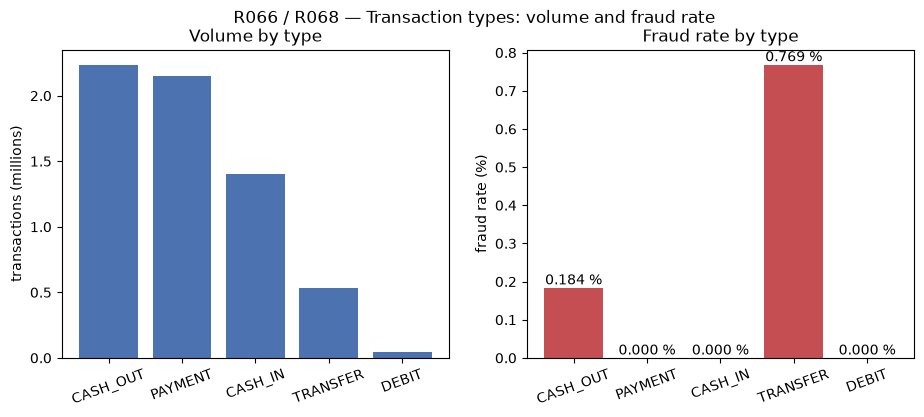

Saved: artifacts/figures/eda2_type_volume_fraud_rate.png


In [11]:
by_type = df.groupby("type")[TARGET_COLUMN].agg(count="size", frauds="sum")
by_type["fraud_rate_pct"] = 100 * by_type["frauds"] / by_type["count"]
by_type["share_of_all_frauds_pct"] = 100 * by_type["frauds"] / by_type["frauds"].sum()
by_type = by_type.sort_values("count", ascending=False)
print(by_type.to_string())
fraud_types = sorted(by_type.index[by_type["frauds"] > 0])
print("Types with at least one fraud:", fraud_types)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(by_type.index, by_type["count"] / 1e6, color="#4C72B0")
ax1.set_ylabel("transactions (millions)")
ax1.set_title("Volume by type")
ax2.bar(by_type.index, by_type["fraud_rate_pct"], color="#C44E52")
ax2.set_ylabel("fraud rate (%)")
ax2.set_title("Fraud rate by type")
for i, v in enumerate(by_type["fraud_rate_pct"]):
    ax2.text(i, v, f"{v:.3f} %", ha="center", va="bottom")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("R066 / R068 — Transaction types: volume and fraud rate")
save_eda2_fig(fig, "eda2_type_volume_fraud_rate.png")

**Constat.** La fraude n'apparaît que dans deux types : TRANSFER (4097 fraudes, taux 0.7688 %, 49.8843 % de toutes les fraudes) et CASH_OUT (4116 fraudes, taux 0.1840 %, 50.1157 %). PAYMENT, CASH_IN et DEBIT n'ont aucune fraude (0).

**Figure `eda2_type_volume_fraud_rate.png`.**
1. *Ce qu'elle montre* : à gauche le volume par type, à droite le taux de fraude par type ; TRANSFER a le taux le plus élevé (0.7688 %), CASH_OUT en a beaucoup moins (0.1840 %) mais le même nombre de fraudes, et les trois autres types n'en ont aucune.
2. *Implication pour Northstar* : dans ces données, la fraude suit un scénario « virement puis retrait » ; 3 types sur 5 n'ont jamais de fraude, ce qui est propre au simulateur et ne garantit rien pour un vrai système.
3. *Décision éclairée* : la variable `is_risky_type` (TRANSFER ou CASH_OUT) et l'encodage de `type` (I36) ; limite à écrire : un nouveau scénario de fraude sur un autre type ne serait pas appris.

## R069 — 9. Volume et taux de fraude par step

Steps present: 743 (min 1, max 743)
Transactions per step: {'count': 743.0, 'mean': 8563.4, 'std': 13388.7, 'min': 2.0, '25%': 12.0, '50%': 529.0, '75%': 12317.0, 'max': 51352.0}
Frauds per step: {'count': 743.0, 'mean': 11.1, 'std': 5.0, 'min': 0.0, '25%': 8.0, '50%': 10.0, '75%': 14.0, 'max': 40.0}
Fraud rate per step (%): {'count': 743.0, 'mean': 43.925, 'std': 48.956, 'min': 0.0, '25%': 0.075, '50%': 1.916, '75%': 100.0, 'max': 100.0}


Spearman(volume, frauds) per step: 0.18 ; Spearman(volume, fraud rate): -0.95
Steps where EVERY transaction is a fraud: 320 (3,620 transactions)
              count  frauds  fraud_rate_pct
hour_of_day                                
0             71587     300          0.4191
1             27111     358          1.3205
2              9018     372          4.1251
3              2007     326         16.2431
4              1241     274         22.0790
5              1641     366         22.3035
6              3420     358         10.4678
7              8988     328          3.6493
8             26915     368          1.3673
9            283518     341          0.1203
10           425729     375          0.0881
11           445992     324          0.0726
12           483418     339          0.0701
13           468474     346          0.0739
14           439653     353          0.0803
15           416686     341          0.0818
16           441612     345          0.0781
17           439941

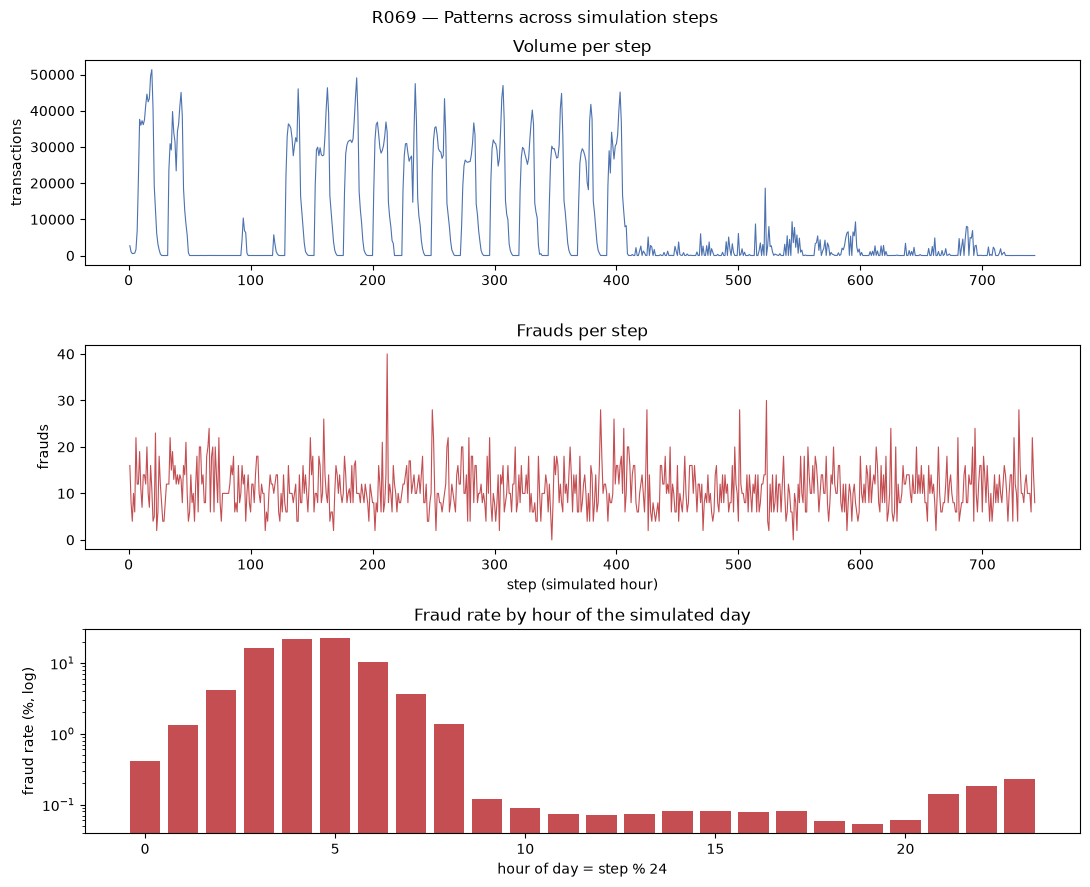

Saved: artifacts/figures/eda2_step_volume_fraud_rate.png


In [12]:
by_step = df.groupby("step")[TARGET_COLUMN].agg(count="size", frauds="sum")
by_step["fraud_rate_pct"] = 100 * by_step["frauds"] / by_step["count"]
print(f"Steps present: {len(by_step)} (min {by_step.index.min()}, max {by_step.index.max()})")
print("Transactions per step:", by_step["count"].describe().round(1).to_dict())
print("Frauds per step:", by_step["frauds"].describe().round(1).to_dict())
print("Fraud rate per step (%):", by_step["fraud_rate_pct"].describe().round(3).to_dict())
# Does the number of frauds follow the volume? (Spearman, computed on the per-step aggregates)
rho_volume_frauds = by_step["count"].corr(by_step["frauds"], method="spearman")
rho_volume_rate = by_step["count"].corr(by_step["fraud_rate_pct"], method="spearman")
print(f"Spearman(volume, frauds) per step: {rho_volume_frauds:.2f} ; Spearman(volume, fraud rate): {rho_volume_rate:.2f}")
all_fraud_steps = by_step[by_step["frauds"] == by_step["count"]]
print(f"Steps where EVERY transaction is a fraud: {len(all_fraud_steps)} ({int(all_fraud_steps['count'].sum()):,} transactions)")
# Hour of the simulated day (hypothesis: 1 step = 1 hour, as the dataset description says).
hour = df["step"] % 24
by_hour = df.groupby(hour)[TARGET_COLUMN].agg(count="size", frauds="sum")
by_hour.index.name = "hour_of_day"
by_hour["fraud_rate_pct"] = 100 * by_hour["frauds"] / by_hour["count"]
print(by_hour.to_string())
del hour

fig, axes = plt.subplots(3, 1, figsize=(11, 9))
axes[0].plot(by_step.index, by_step["count"], color="#4C72B0", lw=0.8)
axes[0].set_ylabel("transactions")
axes[0].set_title("Volume per step")
axes[1].plot(by_step.index, by_step["frauds"], color="#C44E52", lw=0.8)
axes[1].set_ylabel("frauds")
axes[1].set_xlabel("step (simulated hour)")
axes[1].set_title("Frauds per step")
axes[2].bar(by_hour.index, by_hour["fraud_rate_pct"], color="#C44E52")
axes[2].set_yscale("log")
axes[2].set_xlabel("hour of day = step % 24")
axes[2].set_ylabel("fraud rate (%, log)")
axes[2].set_title("Fraud rate by hour of the simulated day")
fig.suptitle("R069 — Patterns across simulation steps")
fig.tight_layout()
save_eda2_fig(fig, "eda2_step_volume_fraud_rate.png")

**Constat.** 743 steps (1 à 743). Le volume varie énormément : de 2 à 51352 transactions par step (médiane 529), avec un cycle quotidien net et une chute du volume dans la dernière partie de la simulation. Le nombre de fraudes, lui, reste presque constant (médiane 10 par step, maximum 40) : la corrélation de Spearman entre le volume et le nombre de fraudes par step n'est que de 0.18, et celle entre le volume et le taux de fraude est de -0.95. Dans 320 steps (3,620 transactions), **toutes** les transactions sont des fraudes. Par heure du jour simulée (`step % 24`), le taux de fraude monte à 22.0790 % (heure 4) et 22.3035 % (heure 5), contre 0.0528 % à l'heure 19.

**Figure `eda2_step_volume_fraud_rate.png`.**
1. *Ce qu'elle montre* : le volume par step suit un cycle jour/nuit, alors que le nombre de fraudes par step reste stable ; le taux de fraude est donc très élevé aux heures creuses (3 h à 6 h).
2. *Implication pour Northstar* : dans le simulateur, une transaction de nuit est beaucoup plus souvent frauduleuse, mais c'est surtout parce que les fraudes sont injectées à rythme constant pendant que l'activité normale baisse ; un vrai fraudeur ne suit pas forcément ce calendrier.
3. *Décision éclairée* : la variable `hour_of_day` remplace `step` brut (I36), mais elle porte un artefact du simulateur (question au fondateur, `PASSATION.md` §6) ; le découpage stratifié aléatoire (I34) mélange les steps, ce que l'énoncé §4.1 signale comme risque (question au fondateur, aucun changement).

## R070 — 10. Corrélation de champs numériques choisis

                step  amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  newbalanceDest  isFraud
step            1.00    0.00          -0.01           -0.01           -0.00           -0.01     0.02
amount          0.00    1.00           0.05           -0.07            0.60            0.67     0.04
oldbalanceOrg  -0.01    0.05           1.00            0.80            0.02           -0.01     0.04
newbalanceOrig -0.01   -0.07           0.80            1.00            0.04           -0.09    -0.03
oldbalanceDest -0.00    0.60           0.02            0.04            1.00            0.94    -0.02
newbalanceDest -0.01    0.67          -0.01           -0.09            0.94            1.00    -0.01
isFraud         0.02    0.04           0.04           -0.03           -0.02           -0.01     1.00


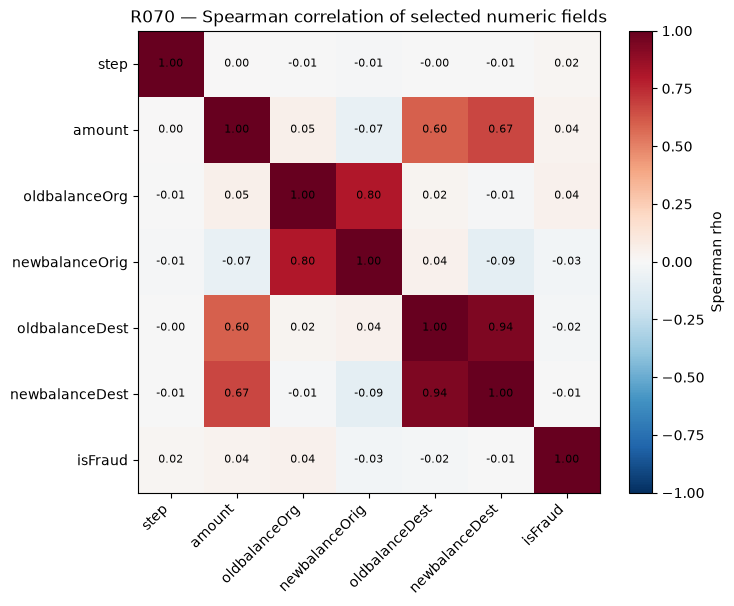

Saved: artifacts/figures/eda2_spearman_correlation.png


In [13]:
NUMERIC_FIELDS = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", TARGET_COLUMN]
spearman = df[NUMERIC_FIELDS].corr(method="spearman")
print(spearman.to_string(float_format=lambda v: f"{v:.2f}"))

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(spearman.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_FIELDS)), NUMERIC_FIELDS, rotation=45, ha="right")
ax.set_yticks(range(len(NUMERIC_FIELDS)), NUMERIC_FIELDS)
for i in range(len(NUMERIC_FIELDS)):
    for j in range(len(NUMERIC_FIELDS)):
        ax.text(j, i, f"{spearman.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman rho")
ax.set_title("R070 — Spearman correlation of selected numeric fields")
save_eda2_fig(fig, "eda2_spearman_correlation.png")

**Champs choisis** : `step`, `amount`, les 4 soldes et `isFraud`. **Méthode** : Spearman (corrélation des rangs), moins sensible que Pearson aux montants extrêmes vus en R067.

**Constat.** Les soldes avant/après sont fortement liés : `oldbalanceOrg`–`newbalanceOrig` 0.80, `oldbalanceDest`–`newbalanceDest` 0.94 ; `amount` est lié aux soldes de destination (0.60 et 0.67). Aucun champ n'a de corrélation forte avec `isFraud` (au plus 0.04 en valeur absolue).

**Limites de la corrélation.** Elle ne mesure qu'une relation monotone entre deux champs, pas une relation conditionnelle (« si TRANSFER et compte vidé ») ; elle ne prouve aucune causalité ; avec une cible binaire très rare, un coefficient faible ne veut pas dire « inutile » (R071 montre des motifs presque parfaits que la corrélation ne voit pas) ; les soldes sont liés par construction (`new = old ± amount`).

**Figure `eda2_spearman_correlation.png`.**
1. *Ce qu'elle montre* : les soldes avant et après sont très corrélés entre eux (0.80 et 0.94), et aucun champ pris seul n'est fortement corrélé à la fraude (au plus 0.04).
2. *Implication pour Northstar* : on ne peut pas repérer la fraude avec une règle sur un seul champ ; il faut combiner les champs, d'où l'intérêt d'un modèle et d'une relecture humaine.
3. *Décision éclairée* : retirer `newbalanceOrig` et `newbalanceDest` après l'analyse VIF (I36, colonnes redondantes) et garder un modèle capable de combinaisons non linéaires (Random Forest, I09).

## R071 — 11. Fuite et artefacts du simulateur

TRANSFER + CASH_OUT rows: 2,770,409 (frauds 8,213)
                                     legitimate_n  legitimate_pct  fraud_n  fraud_pct
origin emptied (newbalanceOrig = 0)       2488603         90.0951     8053    98.0519
amount = whole origin balance                   1          0.0000     8034    97.8205
origin balance error > 1 cent             2499041         90.4730       45     0.5479
destination balance error > 1 cent         558456         20.2178     4618    56.2279
destination old and new balance = 0          1706          0.0618     4076    49.6286


             rows  both_dest_balances_zero_pct  frauds
nameDest                                              
C         4211125                       3.9369    8213
M         2151495                     100.0000       0


isFraud               0     1
isFlaggedFraud               
0               6354407  8197
1                     0    16
Flagged rows: 16 ; flagged and fraud: 16 ; share of frauds flagged: 0.19 %
Types of flagged rows: {'TRANSFER': 16}


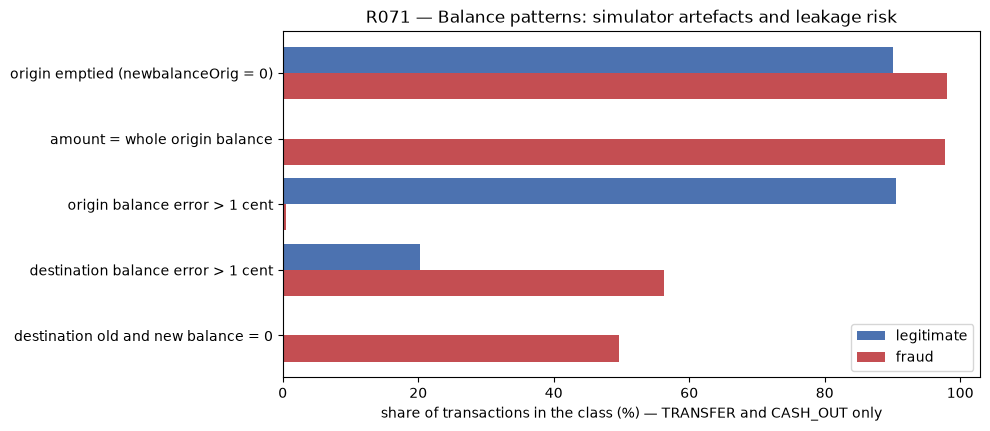

Saved: artifacts/figures/eda2_balance_artefacts.png


In [14]:
# Restricted to TRANSFER and CASH_OUT (the only types with fraud, R068), so that each pattern
# compares fraud and legitimate transactions of the SAME types.
risky = df[df["type"].isin(RISKY_TYPES)]
is_fraud = risky[TARGET_COLUMN] == 1
error_orig = risky["oldbalanceOrg"] - risky["newbalanceOrig"] - risky["amount"]      # same formula as build_features.py
error_dest = risky["oldbalanceDest"] - risky["newbalanceDest"] + risky["amount"]
patterns = pd.DataFrame({
    "origin emptied (newbalanceOrig = 0)": risky["newbalanceOrig"] == 0,
    "amount = whole origin balance": (risky["amount"] - risky["oldbalanceOrg"]).abs() <= CENT,
    "origin balance error > 1 cent": error_orig.abs() > CENT,
    "destination balance error > 1 cent": error_dest.abs() > CENT,
    "destination old and new balance = 0": (risky["oldbalanceDest"] == 0) & (risky["newbalanceDest"] == 0),
})
share = pd.DataFrame({
    "legitimate_n": patterns[~is_fraud].sum(),
    "legitimate_pct": 100 * patterns[~is_fraud].mean(),
    "fraud_n": patterns[is_fraud].sum(),
    "fraud_pct": 100 * patterns[is_fraud].mean(),
})
print(f"TRANSFER + CASH_OUT rows: {len(risky):,} (frauds {int(is_fraud.sum()):,})")
print(share.to_string())

# Destination balances recorded as zero: by first letter of nameDest (account category), all types.
dest_letter = df["nameDest"].str[0]
dest_zero = (df["oldbalanceDest"] == 0) & (df["newbalanceDest"] == 0)
by_letter = pd.DataFrame({"rows": dest_letter.value_counts(),
                          "both_dest_balances_zero_pct": 100 * dest_zero.groupby(dest_letter).mean(),
                          "frauds": df[TARGET_COLUMN].groupby(dest_letter).sum()})
print(by_letter.to_string())

# isFlaggedFraud: the simulator's own rule, compared with the label.
flag_table = pd.crosstab(df[FLAG_COLUMN], df[TARGET_COLUMN], rownames=[FLAG_COLUMN], colnames=[TARGET_COLUMN])
print(flag_table.to_string())
n_flag = int(df[FLAG_COLUMN].sum())
n_flag_fraud = int(((df[FLAG_COLUMN] == 1) & (df[TARGET_COLUMN] == 1)).sum())
print(f"Flagged rows: {n_flag:,} ; flagged and fraud: {n_flag_fraud:,} ; share of frauds flagged: {100 * n_flag_fraud / n_fraud:.2f} %")
print("Types of flagged rows:", df.loc[df[FLAG_COLUMN] == 1, "type"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(share))
ax.barh(y - 0.2, share["legitimate_pct"], height=0.4, color="#4C72B0", label="legitimate")
ax.barh(y + 0.2, share["fraud_pct"], height=0.4, color="#C44E52", label="fraud")
ax.set_yticks(y, share.index)
ax.invert_yaxis()
ax.set_xlabel("share of transactions in the class (%) — TRANSFER and CASH_OUT only")
ax.set_title("R071 — Balance patterns: simulator artefacts and leakage risk")
ax.legend()
save_eda2_fig(fig, "eda2_balance_artefacts.png")
del risky, is_fraud, error_orig, error_dest, patterns, dest_letter, dest_zero

**Constat (TRANSFER et CASH_OUT seulement : 2,770,409 lignes, 8,213 fraudes).**
- « Montant = tout le solde d'origine » : 8034 fraudes (97.8205 %) contre 1 seule transaction légitime. C'est un motif **trop beau** : le simulateur vide presque toujours le compte quand il fraude.
- « Écart de solde d'origine > 1 centime » : 90.4730 % des légitimes contre 0.5479 % des fraudes (45). Côté légitime, le solde d'origine n'est presque jamais mis à jour de façon cohérente : c'est un artefact du simulateur, et la variable `error_balance_orig` (I36) le capte.
- « Soldes de destination à 0 avant et après » : 49.6286 % des fraudes (4076) contre 0.0618 % des légitimes (1706).
- Destinataires `M` (marchands) : 2151495 lignes, soldes de destination à 0 dans 100.0000 % des cas et 0 fraude. Leurs soldes ne sont pas enregistrés : un 0 ne veut pas dire « compte vide ».
- `isFlaggedFraud` : 16 lignes signalées, toutes frauduleuses et toutes TRANSFER, mais cela ne couvre que 0.19 % des fraudes (8197 fraudes non signalées). C'est la sortie d'une règle du simulateur : elle reste **exclue** des variables (énoncé §4.2, I36).

**Figure `eda2_balance_artefacts.png`.**
1. *Ce qu'elle montre* : pour 5 motifs de solde, la part des transactions légitimes et frauduleuses (TRANSFER et CASH_OUT) qui les présentent ; « montant = tout le solde » (97.8205 % des fraudes) et « écart de solde d'origine » (90.4730 % des légitimes) séparent presque parfaitement les deux classes.
2. *Implication pour Northstar* : un modèle peut obtenir d'excellents scores sur PaySim en apprenant ces règles de construction du simulateur, qui n'existeraient pas telles quelles dans de vraies transactions ; la performance mesurée surestime sans doute la performance réelle.
3. *Décision éclairée* : `isFlaggedFraud` et les identifiants restent exclus (I36) ; les variables `error_balance_orig` et `error_balance_dest` sont gardées comme décidé au J3, mais leur dépendance à un artefact est une **question au fondateur** (`PASSATION.md` §6) et une limite à écrire au rapport.

## R072 — 12. Valeurs aberrantes et observations inhabituelles

             rows  outliers_low  outliers_high  fraud_rate_outliers_pct  fraud_rate_others_pct
type                                                                                          
CASH_OUT  2237484         84868           1076                   1.3416                 0.1370
PAYMENT   2151495         67310             76                   0.0000                 0.0000
CASH_IN   1399284         53727             10                   0.0000                 0.0000
TRANSFER   532909         13712           5906                   2.2021                 0.7140
DEBIT       41432          1320            629                   0.0000                 0.0000
Total IQR outliers: 228,634
Maximum amount: 92,445,516.64 ; rows at the maximum: 1 ; frauds at the maximum: 0
Maximum fraud amount: 10,000,000.00 ; frauds at exactly this amount: 287 ; legitimate rows at this amount: 2,920
amount > origin balance before (+1 cent): 4,079,079 rows (64.11 %), fraud rate 0.0007 %


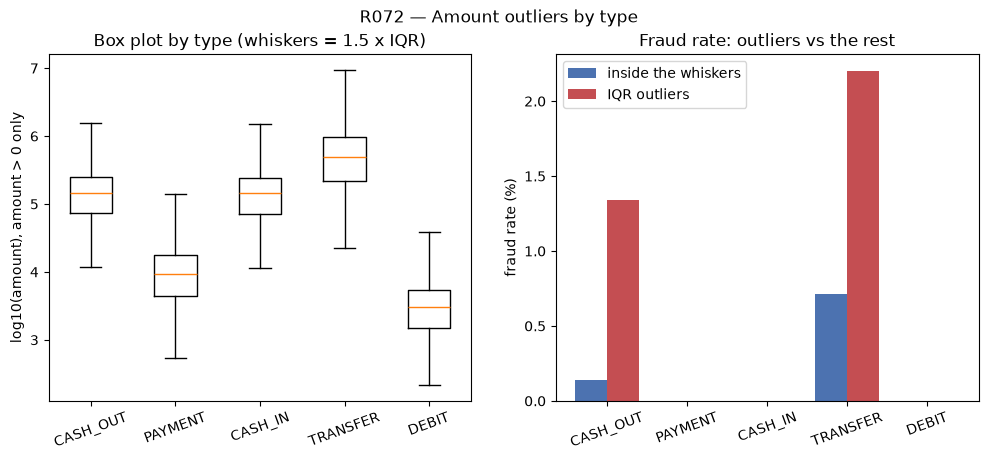

Saved: artifacts/figures/eda2_amount_outliers_by_type.png


In [15]:
# Detection: 1.5 x IQR rule on log10(amount), per type, amount > 0 only (zeros counted in R067).
positive = df.loc[df["amount"] > 0, ["type", "amount", TARGET_COLUMN]]
log_amount = np.log10(positive["amount"])
rows, box_stats = [], []
for t in by_type.index:
    values = log_amount[positive["type"] == t]
    q1, med, q3 = values.quantile([0.25, 0.5, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    is_out = (values < low) | (values > high)
    labels = positive.loc[values.index, TARGET_COLUMN]
    rows.append({"type": t, "rows": len(values), "outliers_low": int((values < low).sum()),
                 "outliers_high": int((values > high).sum()),
                 "fraud_rate_outliers_pct": 100 * labels[is_out].mean() if is_out.any() else float("nan"),
                 "fraud_rate_others_pct": 100 * labels[~is_out].mean()})
    box_stats.append({"label": t, "q1": q1, "med": med, "q3": q3,
                      "whislo": values[values >= low].min(), "whishi": values[values <= high].max(), "fliers": []})
outliers = pd.DataFrame(rows).set_index("type")
print(outliers.to_string())
print(f"Total IQR outliers: {int(outliers[['outliers_low', 'outliers_high']].sum().sum()):,}")
max_amount = df["amount"].max()
at_max = df["amount"] == max_amount
print(f"Maximum amount: {max_amount:,.2f} ; rows at the maximum: {int(at_max.sum()):,} ; frauds at the maximum: {int((at_max & (df[TARGET_COLUMN] == 1)).sum()):,}")
fraud_amounts = df.loc[df[TARGET_COLUMN] == 1, "amount"]
max_fraud = fraud_amounts.max()
print(f"Maximum fraud amount: {max_fraud:,.2f} ; frauds at exactly this amount: {int((fraud_amounts == max_fraud).sum()):,} ; legitimate rows at this amount: {int(((df['amount'] == max_fraud) & (df[TARGET_COLUMN] == 0)).sum()):,}")
over_balance = df["amount"] > df["oldbalanceOrg"] + CENT
print(f"amount > origin balance before (+1 cent): {int(over_balance.sum()):,} rows ({100 * over_balance.mean():.2f} %), fraud rate {100 * df.loc[over_balance, TARGET_COLUMN].mean():.4f} %")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.bxp(box_stats, showfliers=False)
ax1.set_ylabel("log10(amount), amount > 0 only")
ax1.set_title("Box plot by type (whiskers = 1.5 x IQR)")
ax1.tick_params(axis="x", rotation=20)
x = np.arange(len(outliers))
ax2.bar(x - 0.2, outliers["fraud_rate_others_pct"], width=0.4, color="#4C72B0", label="inside the whiskers")
ax2.bar(x + 0.2, outliers["fraud_rate_outliers_pct"].fillna(0), width=0.4, color="#C44E52", label="IQR outliers")
ax2.set_xticks(x, outliers.index, rotation=20)
ax2.set_ylabel("fraud rate (%)")
ax2.set_title("Fraud rate: outliers vs the rest")
ax2.legend()
fig.suptitle("R072 — Amount outliers by type")
save_eda2_fig(fig, "eda2_amount_outliers_by_type.png")
del positive, log_amount, at_max, over_balance, fraud_amounts

**Détection.** Règle 1,5 × IQR sur log10(`amount`), par type, sur `amount > 0` seulement (les 16 montants nuls sont comptés en R067). **Inspection** par agrégats seulement.

**Constat.** 228,634 valeurs aberrantes au total. Elles sont **plus** souvent frauduleuses que le reste : TRANSFER 2.2021 % contre 0.7140 %, CASH_OUT 1.3416 % contre 0.1370 %. Le montant maximum (92,445,516.64) est une seule transaction, légitime. Le montant maximum d'une fraude est 10,000,000.00 : 287 fraudes ont exactement ce montant (et 2,920 transactions légitimes aussi), ce qui ressemble à un plafond du simulateur (hypothèse, non vérifiée dans la documentation). Enfin, 4,079,079 transactions (64.11 %) ont un montant supérieur au solde d'origine avant la transaction, avec un taux de fraude de 0.0007 % : incohérence du simulateur côté légitime.

**Figure `eda2_amount_outliers_by_type.png`.**
1. *Ce qu'elle montre* : à gauche la boîte à moustaches de log10(`amount`) par type (montants > 0 seulement) ; à droite, le taux de fraude des valeurs aberrantes comparé au reste, plus élevé pour TRANSFER (2.2021 % contre 0.7140 %) et CASH_OUT (1.3416 % contre 0.1370 %).
2. *Implication pour Northstar* : les montants extrêmes sont justement là où la fraude est la plus fréquente ; les retirer ou les écrêter ferait perdre des cas que les relecteurs doivent voir.
3. *Décision éclairée* : **aucun traitement** des valeurs aberrantes (pas de suppression, pas d'écrêtage) ; la transformation logarithmique signée du pipeline (J3) réduit leur poids, et la Random Forest (I09) est peu sensible aux valeurs extrêmes.

## A08 — Constats → décisions

| # | Constat (section) | Décision | Lien J3 |
|---|---|---|---|
| 1 | 11 colonnes conformes au contrat, types cohérents avec leur sens (R061, R062) | Aucune correction ; schéma validé à chaque chargement par `load_raw()` | contrat J2 |
| 2 | 0 valeur manquante (R063) | Aucune imputation ; règle documentée : rien à traiter (R081) | confirmé |
| 3 | D1 = 0, D2 = 0, 0 groupe à étiquette contradictoire (R064) | Aucune ligne retirée (R082) | confirmé |
| 4 | 0.1291 % de fraudes, 1 pour 774 (R065) | PR-AUC, précision et rappel ; découpage stratifié | I09, I08, I34 confirmés |
| 5 | Fraude seulement en TRANSFER et CASH_OUT (R068) | `is_risky_type` + encodage de `type` ; limite : autres scénarios non appris | I36 confirmé |
| 6 | Montants très asymétriques (30.99), 16 montants nuls tous frauduleux (R067) | Log signé dans le pipeline, montants nuls gardés | I36 confirmé |
| 7 | Soldes avant/après corrélés (0.80, 0.94) (R070) | `newbalanceOrig`, `newbalanceDest` retirés après VIF | I36 confirmé |
| 8 | `nameOrig` presque toujours unique, `nameDest` réutilisé (R064) | Identifiants exclus des variables | I36 confirmé |
| 9 | `isFlaggedFraud` : 16 lignes, 0.19 % des fraudes, règle du simulateur (R071) | Exclu des variables | I36 confirmé |
| 10 | Taux de fraude par heure de 0.0528 % à 22.3035 %, fraudes constantes par step (R069) | `hour_of_day` gardé ; artefact signalé | **question au fondateur** (I36) |
| 11 | Écart de solde d'origine : 90.4730 % des légitimes contre 0.5479 % des fraudes (R071) | `error_balance_orig` / `error_balance_dest` gardés ; artefact signalé | **question au fondateur** (I36) |
| 12 | Découpage aléatoire stratifié alors que le volume change fortement selon le step (R069) | Rien changé | **question au fondateur** (I34) |
| 13 | Valeurs aberrantes plus souvent frauduleuses ; plafond apparent à 10,000,000.00 (R072) | Aucun traitement ; limite écrite | confirmé |
| 14 | Soldes `M` toujours à 0, montant > solde d'origine dans 64.11 % des lignes (R071, R072) | Aucun traitement ; limites du jeu de données | limite (README) |

Aucune décision J3 n'est modifiée par ce notebook. Les lignes 10 à 12 sont des questions au fondateur (`PASSATION.md` §6).

In [16]:
written = sorted(p.name for p in FIG_DIR.glob("eda2_*.png"))
print(f"eda2_ figures in {FIG_DIR}: {len(written)}")
for name in written:
    print(" -", name)
print(f"Time since loading started: {time.perf_counter() - t0:.0f} s")

eda2_ figures in artifacts/figures: 7
 - eda2_amount_distribution.png
 - eda2_amount_outliers_by_type.png
 - eda2_balance_artefacts.png
 - eda2_class_imbalance.png
 - eda2_spearman_correlation.png
 - eda2_step_volume_fraud_rate.png
 - eda2_type_volume_fraud_rate.png
Time since loading started: 63 s
